# 15. Velocidad de Caída de Sedimentos y Curvas Granulométricas (`sedmor.sediments`)

Este cuaderno reúne las herramientas fundamentales de caracterización física e hidráulica de sedimentos en `sedmor.sediments`:

1. **Propiedades agua–sedimento y velocidad de caída ($w_s$)**:
   - Viscosidad cinemática $\nu(T)$ y densidad $\rho_w(T, S)$, diálogo adimensional $D_*$.
   - Comparación entre **Stokes (1851)**, **van Rijn (1993)**, **Soulsby (1997)**, **Ferguson y Church (2004)** y **Rubey (1933)**.
   - Caída obstaculizada (*hindered settling*, Richardson y Zaki) y floculación de fangos cohesivos.
2. **Herramientas de curvas granulométricas**:
   - Conversión de tamizado en masas retenidas a % pasante, escala $\phi$ y clasificación **Wentworth (1922)**.
   - Percentiles ($D_{10}, D_{16}, D_{50}, D_{84}, D_{90}$), coeficientes de **Hazen** ($C_u, C_c$) y estadísticos gráficos de **Folk y Ward (1957)** ($M_z, \sigma_I, Sk_I, K_G$).
   - Mezcla de curvas (`blend_grain_size_curves`) y verificación de filtros de **Terzaghi** (`check_filter_compatibility`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110


## 1. Modelos de velocidad de caída, efecto de temperatura y floculación

Comparamos los cinco modelos de velocidad de caída en agua clara a $20\,^\circ\text{C}$ desde limos ($10\,\mu\text{m}$) hasta gravas ($20\,\text{mm}$), evaluamos el efecto de la temperatura ($5\,^\circ\text{C}$ vs $25\,^\circ\text{C}$) y mostramos la curva de floculación y frenado en sedimentos cohesivos.


Arena 0.25 mm (20 °C, agua mar): van Rijn=0.0326 | Soulsby=0.0332 | Ferguson=0.0295 m/s
Efecto temperatura en arena fina 0.18 mm: ws(5 °C)=0.0146 m/s vs ws(25 °C)=0.0212 m/s (+45%)


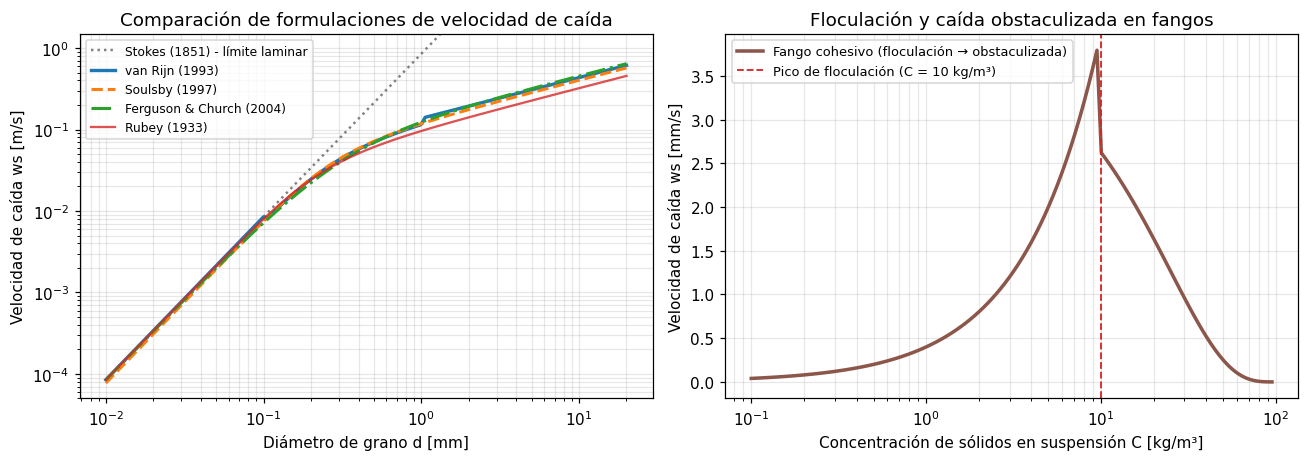

In [2]:
d_m = np.geomspace(1e-5, 2e-2, 120)
nu_20 = sm.sediments.water_kinematic_viscosity(20.0)
nu_5 = sm.sediments.water_kinematic_viscosity(5.0)
nu_25 = sm.sediments.water_kinematic_viscosity(25.0)
rho_mar = sm.sediments.water_density(15.0, salinity_psu=35.0)

cmp20 = sm.sediments.compare_fall_velocity_models(d_m, rho_w=rho_mar, nu=nu_20)
fc_5c = sm.sediments.fall_velocity_ferguson_church(0.00018, nu=nu_5).ws_clear_m_s
fc_25c = sm.sediments.fall_velocity_ferguson_church(0.00018, nu=nu_25).ws_clear_m_s

idx_sand = int(np.argmin(np.abs(d_m - 0.00025)))
print(
    f"Arena 0.25 mm (20 °C, agua mar): van Rijn={cmp20['van_rijn_m_s'][idx_sand]:.4f} | "
    f"Soulsby={cmp20['soulsby_m_s'][idx_sand]:.4f} | Ferguson={cmp20['ferguson_church_m_s'][idx_sand]:.4f} m/s"
)
print(f"Efecto temperatura en arena fina 0.18 mm: ws(5 °C)={fc_5c:.4f} m/s vs ws(25 °C)={fc_25c:.4f} m/s (+{100*(fc_25c/fc_5c - 1):.0f}%)")

c_mud = np.geomspace(0.1, 95.0, 120)
ws_mud = sm.sediments.flocculated_settling_velocity(c_mud, ws_base=0.0004, c_floc_max=10.0, c_gel=100.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
d_mm = d_m * 1000.0
ax1.loglog(d_mm, cmp20["stokes_m_s"], ":", lw=1.6, color="gray", label="Stokes (1851) - límite laminar")
ax1.loglog(d_mm, cmp20["van_rijn_m_s"], lw=2.2, label="van Rijn (1993)")
ax1.loglog(d_mm, cmp20["soulsby_m_s"], "--", lw=2.0, label="Soulsby (1997)")
ax1.loglog(d_mm, cmp20["ferguson_church_m_s"], "-.", lw=2.0, label="Ferguson & Church (2004)")
ax1.loglog(d_mm, cmp20["rubey_m_s"], lw=1.5, alpha=0.8, label="Rubey (1933)")
ax1.set_ylim(5e-5, 1.5)
ax1.set_xlabel("Diámetro de grano d [mm]")
ax1.set_ylabel("Velocidad de caída ws [m/s]")
ax1.set_title("Comparación de formulaciones de velocidad de caída")
ax1.grid(True, which="both", alpha=0.3)
ax1.legend(fontsize=8.0)

ax2.semilogx(c_mud, ws_mud * 1000.0, lw=2.3, color="tab:brown", label="Fango cohesivo (floculación → obstaculizada)")
ax2.axvline(10.0, color="tab:red", ls="--", lw=1.2, label="Pico de floculación (C = 10 kg/m³)")
ax2.set_xlabel("Concentración de sólidos en suspensión C [kg/m³]")
ax2.set_ylabel("Velocidad de caída ws [mm/s]")
ax2.set_title("Floculación y caída obstaculizada en fangos")
ax2.grid(True, which="both", alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 2. Análisis de tamizado, estadísticos de Folk y Ward, mezcla y filtro granular

Procesamos una muestra real de tamizado expresada en **gramos retenidos** sobre cada malla (incluyendo material de fondo), calculamos percentiles, coeficientes de Hazen y parámetros de **Folk y Ward (1957)**, la mezclamos en proporción `60% / 40%` con un préstamo más grueso y evaluamos compatibilidad de **filtro granular de Terzaghi** frente a un material grueso protector.


Muestra laboratorio: D10=0.195 mm | D50=0.626 mm (Arena gruesa (0.5–1 mm)) | D90=2.000 mm
Hazen: Cu=3.87 | Cc=1.11 | Gradación: Mal graduado / Uniforme (P)
Folk & Ward: Mz=0.64 φ (0.641 mm) | σ_I=1.40 (Pobremente seleccionado) | Sk_I=+0.01 | K_G=1.42
Textura: Grava=10.0% | Arena=86.0% | Finos=4.0%
Mezcla 60/40: D50=0.837 mm | Cu=3.46
Filtro Terzaghi: D15f/D85b=0.91 (<=5) | D15f/D15b=5.33 (>=5) | Compatible=True


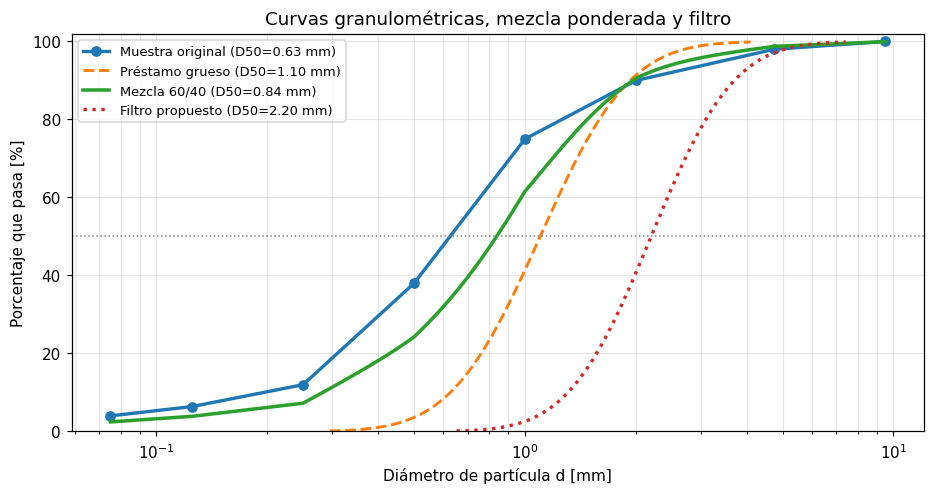

In [3]:
# Datos de laboratorio: masas retenidas por tamiz [g] + fondo (pan)
tamices_mm = np.array([0.075, 0.125, 0.25, 0.50, 1.00, 2.00, 4.75, 9.50])
masas_g = np.array([12.0, 28.0, 130.0, 185.0, 75.0, 40.0, 10.0, 0.0])  # + 20 g en fondo = 500 g total

muestra = sm.sediments.grain_size_curve_statistics(
    tamices_mm, masas_g, input_type="retained_mass", pan_value=20.0
)

print(
    f"Muestra laboratorio: D10={muestra.d10_mm:.3f} mm | D50={muestra.d50_mm:.3f} mm ({sm.sediments.classify_grain_size_wentworth(muestra.d50_mm)}) | "
    f"D90={muestra.d90_mm:.3f} mm"
)
print(
    f"Hazen: Cu={muestra.cu_uniformity:.2f} | Cc={muestra.cc_curvature:.2f} | Gradación: {muestra.uscs_gradation}"
)
print(
    f"Folk & Ward: Mz={muestra.folk_ward_mean_phi:.2f} φ ({muestra.folk_ward_mean_mm:.3f} mm) | "
    f"σ_I={muestra.folk_ward_sorting_phi:.2f} ({muestra.sorting_class}) | Sk_I={muestra.folk_ward_skewness:+.2f} | K_G={muestra.folk_ward_kurtosis:.2f}"
)
print(f"Textura: Grava={muestra.gravel_pct:.1f}% | Arena={muestra.sand_pct:.1f}% | Finos={muestra.fines_pct:.1f}%")

# Préstamo más grueso y mezcla 60/40; y verificación de un filtro grueso respecto a la muestra base
prestamo = sm.sediments.lognormal_grain_size_curve(d50_mm=1.10, sigma_g=1.55, n_points=61)
mezcla = sm.sediments.blend_grain_size_curves(
    [(muestra.diameters_mm, muestra.percent_passing), (prestamo.diameters_mm, prestamo.percent_passing)],
    weights=[0.60, 0.40],
)
filtro = sm.sediments.lognormal_grain_size_curve(d50_mm=2.20, sigma_g=1.50, n_points=61)
compat = sm.sediments.check_filter_compatibility(
    muestra.diameters_mm, muestra.percent_passing, filtro.diameters_mm, filtro.percent_passing
)

print(
    f"Mezcla 60/40: D50={mezcla.d50_mm:.3f} mm | Cu={mezcla.cu_uniformity:.2f}\n"
    f"Filtro Terzaghi: D15f/D85b={compat['retention_ratio_D15f_D85b']:.2f} (<=5) | "
    f"D15f/D15b={compat['permeability_ratio_D15f_D15b']:.2f} (>=5) | Compatible={compat['is_compatible']}"
)

fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.semilogx(muestra.diameters_mm, muestra.percent_passing, "o-", lw=2.2, label=f"Muestra original (D50={muestra.d50_mm:.2f} mm)")
ax.semilogx(prestamo.diameters_mm, prestamo.percent_passing, "--", lw=1.9, label=f"Préstamo grueso (D50={prestamo.d50_mm:.2f} mm)")
ax.semilogx(mezcla.diameters_mm, mezcla.percent_passing, lw=2.3, label=f"Mezcla 60/40 (D50={mezcla.d50_mm:.2f} mm)")
ax.semilogx(filtro.diameters_mm, filtro.percent_passing, ":", lw=2.2, label=f"Filtro propuesto (D50={filtro.d50_mm:.2f} mm)")
ax.axhline(50.0, color="gray", ls=":", lw=1.0)
ax.set_xlabel("Diámetro de partícula d [mm]")
ax.set_ylabel("Porcentaje que pasa [%]")
ax.set_title("Curvas granulométricas, mezcla ponderada y filtro")
ax.set_ylim(0, 102)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()
